# 11 — Knowledge Base Retrieval (bge-m3 + FAISS)

## 1. Introduction and objectives

This notebook (Phase 4a) evaluates the *Knowledge base* box of the data layer: the documents
the advisor agent searches before answering a customer.

The knowledge base is real code in `src/callverse/agents/advisor/` (`indexing.py`,
`retrieval.py`, tested in `tests/unit/test_knowledge_base.py`), built by
`scripts/build_knowledge_base.py` from the Markdown documents in `data/knowledge_base/docs/`.
This notebook:

1. Describes the documents and chunks.
2. Measures retrieval quality on **real-style customer messages** (Bitext) for the 17
   order-linked intents, and compares bge-m3 with two cheaper baselines.
3. Checks **French** queries against the English documents.
4. Calibrates a **minimum score** below which the advisor should say it has no answer.

**Decisions (version 1)**

| Topic | Decision |
|---|---|
| Documents | Synthetic policies of a fictional store, grounded in Olist facts (statuses, payment types, delivery times); every rule is an explicit assumption |
| Language | English documents (as for contacts, `configs/data.yaml`); bge-m3 is multilingual, so French questions still work |
| Chunking | One chunk per `##` section; each section carries the intents it answers |
| Index | FAISS `IndexFlatIP` on normalised vectors = exact cosine search |
| Relevance label | A retrieved chunk is relevant when it is tagged with the query's intent |

> **Limit of the evaluation.** The intent tags were written together with the documents, so
> this measures whether the search finds the section *we intended* for each kind of
> question. It does not check that the policy text itself is correct or complete.

## 2. Imports, paths and inputs

In [1]:
%matplotlib inline
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch  # noqa: F401  (imported early: avoids a Windows DLL clash with pyarrow)
import yaml
from sklearn.feature_extraction.text import TfidfVectorizer

from callverse.agents.advisor import (
    KnowledgeRetriever,
    SentenceTransformerEmbedder,
    build_index,
    load_chunks,
    load_knowledge_base_config,
)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_BITEXT = (PROJECT_ROOT / "data" / "raw" / "bitext"
              / "bitext-retail-ecommerce-llm-chatbot-training-dataset.csv")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
EVAL_DIR = PROJECT_ROOT / "artifacts" / "evaluations"
AGENTS_CONFIG = PROJECT_ROOT / "configs" / "agents.yaml"
DATA_CONFIG = PROJECT_ROOT / "configs" / "data.yaml"

kb_config = load_knowledge_base_config(AGENTS_CONFIG, PROJECT_ROOT)
required_files = [RAW_BITEXT, PROCESSED_DIR / "bitext_intent_catalog.csv",
                  kb_config.index_dir / "index.faiss", kb_config.index_dir / "manifest.json"]
missing = [str(path) for path in required_files if not path.exists()]
assert not missing, f"Missing inputs (run scripts/build_knowledge_base.py): {missing}"

with open(DATA_CONFIG, encoding="utf-8") as config_file:
    contacts_config = yaml.safe_load(config_file)["generation"]["contacts"]
INTENT_GROUPS = contacts_config["intent_groups"]
ORDER_INTENTS = sorted(i for intents in INTENT_GROUPS.values() for i in intents)
EXCLUDED_TAGS = contacts_config["messages"]["exclude_tags"]
SEED = contacts_config["random_seed"]
TOP_K = kb_config.top_k
print(f"{len(ORDER_INTENTS)} order-linked intents, top_k = {TOP_K}, seed = {SEED}")

17 order-linked intents, top_k = 4, seed = 42


## 3. Documents and chunks

The retriever loads the saved index; the index refuses to load if a document changed after
it was built (SHA-256 check in the manifest).

In [2]:
retriever = KnowledgeRetriever.from_config(kb_config)
chunks = retriever.chunks
chunk_table = pd.DataFrame([{
    "doc_id": c.doc_id, "doc_type": c.doc_type, "section": c.section,
    "n_intents": len(c.intents), "chars": len(c.text)} for c in chunks])

print(f"{chunk_table.doc_id.nunique()} documents, {len(chunks)} chunks, "
      f"embedding dimension {retriever.index.d}")
chunk_table.groupby(["doc_id", "doc_type"]).agg(
    chunks=("section", "size"), mean_chars=("chars", "mean"), max_chars=("chars", "max")
).round(0).astype({"mean_chars": int, "max_chars": int})

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

10 documents, 58 chunks, embedding dimension 1024


,,chunks,mean_chars,max_chars
doc_id,doc_type,,,
advisor_playbook,procedure,5,330,434
cancellations_and_order_changes,policy,6,316,466
customer_faq,faq,10,222,316
damaged_wrong_missing_items,policy,5,436,593
delivery_times_and_delays,policy,6,462,698
invoices,policy,4,284,396
order_status_and_tracking,policy,5,525,893
payment_policy,policy,6,373,502
refund_policy,policy,5,471,724


In [3]:
coverage = pd.Series({intent: sum(intent in c.intents for c in chunks)
                      for intent in ORDER_INTENTS}, name="chunks_tagged")
coverage.sort_values().to_frame().T

,damaged_delivery,missing_item,product_issue,return_product_online,exchange_product,wrong_item,request_invoice,request_refund,change_order,cancel_order,return_product,track_delivery,delivery_time,refund_status,delivery_issue,payment_issue,track_order
chunks_tagged,3,3,4,4,4,4,5,5,5,5,6,6,6,7,8,8,8


Every intent is answered by at least two chunks (one policy section and one FAQ answer at
least). Sections are short (a few hundred characters), well below the 512-token limit set for
the model, so no text is truncated.

## 4. Test queries

- **In scope:** Bitext messages of the 17 order-linked intents, 60 per intent (stratified
  sample, fixed seed), without the offensive-language tag `W` (same rule as the contact
  generator).
- **Out of scope:** Bitext messages of intents the knowledge base does not cover (account,
  password, cart, product questions...), 10 per intent. They are used in section 8 to choose a
  "no answer" threshold.

Bitext messages contain placeholders such as `{{Order Number}}`; they are kept as they are,
because they look like the anonymised text a real system would receive.

In [4]:
bitext = pd.read_csv(RAW_BITEXT)
bitext = bitext[~bitext["tags"].fillna("").str.contains("|".join(EXCLUDED_TAGS))]
catalog = pd.read_csv(PROCESSED_DIR / "bitext_intent_catalog.csv")
out_of_scope_intents = sorted(catalog.loc[catalog.proposed_scope == "general", "intent"])

def sample_per_intent(frame, n):
    return pd.concat(group.sample(n, random_state=SEED)
                     for _, group in frame.groupby("intent")).reset_index(drop=True)


in_scope = sample_per_intent(bitext[bitext.intent.isin(ORDER_INTENTS)], 60)
out_scope = sample_per_intent(bitext[bitext.intent.isin(out_of_scope_intents)], 10)
print(f"in scope: {len(in_scope)} queries, {in_scope.intent.nunique()} intents")
print(f"out of scope: {len(out_scope)} queries, {out_scope.intent.nunique()} intents")
in_scope[["intent", "instruction"]].sample(5, random_state=SEED)

in scope: 1020 queries, 17 intents
out of scope: 240 queries, 24 intents


,intent,instruction
523,product_issue,my product doesnt work where could i reporft a...
602,request_invoice,"I purchased an item and I didn't get a bill, ..."
526,product_issue,i have to report an issue with a product how c...
31,cancel_order,i have to cancel an online order
616,request_invoice,I purchased a product and I did not get a bill...


## 5. Methods compared

All three use the same chunks, the same FAISS search code (`KnowledgeRetriever`) and the same
`Embedder` protocol; only the vectors change.

| Method | What it is | Why it is here |
|---|---|---|
| TF-IDF | Word-count vectors fitted on the chunks | Lexical baseline: finds shared words only |
| all-MiniLM-L6-v2 | Small English sentence model (22M parameters, 384 dim) | Cheap semantic baseline |
| **bge-m3** | Multilingual model (568M parameters, 1024 dim) | Chosen model |

In [5]:
class TfidfEmbedder:
    """TF-IDF vectors fitted on the chunk texts, as a lexical baseline."""

    model_name = "tfidf"

    def __init__(self, corpus):
        self.vectorizer = TfidfVectorizer(sublinear_tf=True, stop_words="english")
        self.vectorizer.fit(corpus)

    def encode(self, texts):
        vectors = self.vectorizer.transform(texts).toarray().astype(np.float32)
        norms = np.linalg.norm(vectors, axis=1, keepdims=True)
        return vectors / np.where(norms == 0, 1, norms)


def make_retriever(embedder):
    return KnowledgeRetriever(chunks, build_index(chunks, embedder), embedder, TOP_K)


corpus = [c.embedding_text() for c in chunks]
retrievers = {
    "tfidf": make_retriever(TfidfEmbedder(corpus)),
    "minilm": make_retriever(SentenceTransformerEmbedder("sentence-transformers/all-MiniLM-L6-v2")),
    "bge-m3": retriever,
}

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

## 6. Retrieval quality on in-scope questions

For each query, with the top 4 chunks returned:

- **hit@1**: the best chunk is tagged with the query's intent;
- **hit@4**: at least one of the 4 chunks is (the advisor sees all 4);
- **MRR@4**: mean of 1 / rank of the first relevant chunk (0 if none in the top 4).

95% intervals are bootstrap intervals over queries (1,000 resamples).

In [6]:
def evaluate(retriever, queries, intents):
    start = time.perf_counter()
    results = retriever.search_many(list(queries), top_k=TOP_K)
    seconds = time.perf_counter() - start
    rows = []
    for query, intent, hits in zip(queries, intents, results):
        relevant = [h.rank for h in hits if intent in h.chunk.intents]
        rows.append({
            "query": query, "intent": intent,
            "hit_at_1": float(bool(relevant) and relevant[0] == 1),
            "hit_at_k": float(bool(relevant)),
            "rr": 1 / relevant[0] if relevant else 0.0,
            "top1_score": hits[0].score if hits else np.nan,
            "top1_chunk": hits[0].chunk.chunk_id if hits else None,
            "top1_intents": ",".join(hits[0].chunk.intents) if hits else "",
        })
    return pd.DataFrame(rows), seconds / len(queries)


def bootstrap_ci(values, rng, n=1000):
    values = np.asarray(values)
    means = rng.choice(values, (n, len(values))).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


rng = np.random.default_rng(SEED)
per_query, summary = {}, []
for name, method in retrievers.items():
    per_query[name], seconds_per_query = evaluate(method, in_scope.instruction, in_scope.intent)
    row = {"method": name, "ms_per_query": 1000 * seconds_per_query}
    for metric in ["hit_at_1", "hit_at_k", "rr"]:
        values = per_query[name][metric]
        low, high = bootstrap_ci(values, rng)
        row[metric] = values.mean()
        row[f"{metric}_ci"] = f"[{low:.3f}, {high:.3f}]"
    summary.append(row)

summary = pd.DataFrame(summary).rename(columns={"rr": "mrr", "rr_ci": "mrr_ci",
                                                "hit_at_k": "hit_at_4", "hit_at_k_ci": "hit_at_4_ci"})
summary.round(3)

,method,ms_per_query,hit_at_1,hit_at_1_ci,hit_at_4,hit_at_4_ci,mrr,mrr_ci
0,tfidf,0.040,0.526,"[0.495, 0.557]",0.799,"[0.775, 0.823]",0.639,"[0.616, 0.662]"
1,minilm,3.015,0.782,"[0.757, 0.806]",0.963,"[0.950, 0.975]",0.860,"[0.842, 0.875]"
2,bge-m3,50.802,0.837,"[0.815, 0.862]",0.969,"[0.959, 0.978]",0.892,"[0.876, 0.907]"


In [7]:
per_intent = pd.DataFrame({name: frame.groupby("intent").hit_at_1.mean()
                           for name, frame in per_query.items()})
per_intent["bge-m3 hit@4"] = per_query["bge-m3"].groupby("intent").hit_at_k.mean()
per_intent.sort_values("bge-m3").round(2)

,tfidf,minilm,bge-m3,bge-m3 hit@4
intent,,,,
delivery_issue,0.30,0.42,0.18,0.97
track_order,0.05,0.63,0.35,0.72
request_refund,0.48,0.47,0.38,0.88
delivery_time,0.58,0.82,0.75,1.00
return_product,0.20,0.82,0.82,0.95
request_invoice,0.32,0.93,0.92,1.00
cancel_order,0.70,0.93,0.97,0.98
wrong_item,0.88,0.93,0.97,0.97
payment_issue,0.67,0.95,0.97,1.00


## 7. Error analysis (bge-m3)

Which intent's chunk came first when the right one did not? Most misses should be between
neighbouring intents (for example `track_order` and `track_delivery`), which share sections
and are often answered by the same text.

In [8]:
misses = per_query["bge-m3"].query("hit_at_1 == 0").copy()
misses["top1_doc_section"] = misses.top1_chunk.map(
    {c.chunk_id: f"{c.doc_id} > {c.section}" for c in chunks})
print(f"{len(misses)} top-1 misses out of {len(per_query['bge-m3'])} queries")
(misses.groupby(["intent", "top1_doc_section"]).size()
 .rename("queries").sort_values(ascending=False).head(12).to_frame())

166 top-1 misses out of 1020 queries


,,queries
intent,top1_doc_section,
delivery_issue,"customer_faq > My product arrived damaged, wrong or incomplete.",42
track_order,"returns_and_exchanges > Exchanging a product for another size, colour or model",29
request_refund,advisor_playbook > Compensation authority,28
delivery_time,customer_faq > Where is my order?,11
request_refund,refund_policy > Checking the status of a refund,9
track_order,customer_faq > My order is late or did not arrive. What can I do?,7
delivery_issue,damaged_wrong_missing_items > Missing item in an order,6
delivery_time,order_status_and_tracking > How a customer can check where their order is,4
return_product,refund_policy > When a customer is entitled to a refund,4


In [9]:
pd.set_option("display.max_colwidth", 90)
misses[["intent", "query", "top1_doc_section"]].sample(min(8, len(misses)), random_state=SEED)

,intent,query,top1_doc_section
697,request_refund,i want arefund could ya help me requesting it,advisor_playbook > Compensation authority
917,track_order,"I have to check the status of my replacement product, will you help me?","returns_and_exchanges > Exchanging a product for another size, colour or model"
663,request_refund,im looking for a refund can uhelp me findiung it,refund_policy > Checking the status of a refund
253,delivery_time,i want hepl checking the delivery time of my purchase,order_status_and_tracking > How a customer can check where their order is
693,request_refund,"I want to get a reimbursement, I need help",advisor_playbook > Compensation authority
212,delivery_issue,i did not receive my delivery help mew report a delivery problem,"customer_faq > My product arrived damaged, wrong or incomplete."
707,request_refund,"I want to get a reimbursement, can you help me?",advisor_playbook > Compensation authority
668,request_refund,would it be possible to get an reimbursement,advisor_playbook > Compensation authority


## 8. French questions

The documents are in English. Customers of a French or Brazilian-facing store may write in
another language, so we test 34 French questions written for this notebook (two per intent).
This is a small, illustrative test set.

In [10]:
french_queries = [
    ("track_order", "Où en est ma commande ?"),
    ("track_order", "Quel est le statut de ma commande numéro 12345 ?"),
    ("track_delivery", "Mon numéro de suivi ne fonctionne pas."),
    ("track_delivery", "Où se trouve mon colis en ce moment ?"),
    ("delivery_time", "Quand vais-je recevoir ma commande ?"),
    ("delivery_time", "Combien de jours faut-il pour la livraison ?"),
    ("delivery_issue", "Mon colis est indiqué livré mais je ne l'ai jamais reçu."),
    ("delivery_issue", "La date de livraison prévue est dépassée et rien n'est arrivé."),
    ("cancel_order", "Je veux annuler ma commande."),
    ("cancel_order", "Comment annuler un achat que je viens de faire ?"),
    ("change_order", "Je me suis trompé d'adresse de livraison, puis-je la modifier ?"),
    ("change_order", "Je voudrais changer la taille de l'article commandé."),
    ("request_refund", "Je veux être remboursé."),
    ("request_refund", "Comment obtenir un remboursement pour ma commande ?"),
    ("refund_status", "Où en est mon remboursement ?"),
    ("refund_status", "Je n'ai toujours pas reçu l'argent de mon remboursement."),
    ("return_product", "Je souhaite renvoyer un produit."),
    ("return_product", "Puis-je retourner un article après deux semaines ?"),
    ("return_product_online", "Comment faire un retour en ligne ?"),
    ("return_product_online", "Je n'arrive pas à imprimer l'étiquette de retour."),
    ("exchange_product", "Je voudrais échanger mon article contre une autre couleur."),
    ("exchange_product", "Comment faire un échange de taille ?"),
    ("product_issue", "Le produit que j'ai reçu ne fonctionne pas."),
    ("product_issue", "Mon appareil est tombé en panne après un mois."),
    ("damaged_delivery", "Mon colis est arrivé abîmé."),
    ("damaged_delivery", "L'article est cassé à la livraison."),
    ("wrong_item", "J'ai reçu le mauvais article."),
    ("wrong_item", "Ce n'est pas le produit que j'ai commandé."),
    ("missing_item", "Il manque un article dans ma commande."),
    ("missing_item", "Je n'ai reçu qu'une partie de ma commande."),
    ("payment_issue", "J'ai été débité deux fois."),
    ("payment_issue", "Ma carte a été refusée lors du paiement."),
    ("request_invoice", "Où puis-je télécharger ma facture ?"),
    ("request_invoice", "Je n'ai pas reçu la facture de mon achat."),
]
french = pd.DataFrame(french_queries, columns=["intent", "query"])
assert set(french.intent) == set(ORDER_INTENTS)

french_summary = []
for name, method in retrievers.items():
    frame, _ = evaluate(method, french["query"], french.intent)
    french_summary.append({"method": name, "hit_at_1": frame.hit_at_1.mean(),
                           "hit_at_4": frame.hit_at_k.mean(), "mrr": frame.rr.mean()})
french_summary = pd.DataFrame(french_summary)
french_summary.round(3)

,method,hit_at_1,hit_at_4,mrr
0,tfidf,0.147,0.559,0.304
1,minilm,0.206,0.412,0.287
2,bge-m3,0.941,1.000,0.966


## 9. When to say "I have no answer"

The advisor must not answer a password or shopping-cart question with the refund policy.
The **top-1 cosine score** is compared for in-scope and out-of-scope questions; a minimum
score (`min_score` in `configs/agents.yaml`) turns low-confidence results into "no answer".

In [11]:
out_frame, _ = evaluate(retriever, out_scope.instruction, out_scope.intent)
scores = pd.concat([
    pd.DataFrame({"score": per_query["bge-m3"].top1_score, "scope": "in scope"}),
    pd.DataFrame({"score": out_frame.top1_score, "scope": "out of scope"}),
])

thresholds = np.round(np.arange(0.40, 0.66, 0.01), 2)
in_scores = per_query["bge-m3"].top1_score.to_numpy()
out_scores = out_frame.top1_score.to_numpy()
threshold_table = pd.DataFrame({
    "min_score": thresholds,
    "in_scope_kept": [(in_scores >= t).mean() for t in thresholds],
    "out_scope_rejected": [(out_scores < t).mean() for t in thresholds],
})
threshold_table["balanced_accuracy"] = threshold_table[["in_scope_kept", "out_scope_rejected"]].mean(axis=1)
# Keep at least 95% of in-scope questions answered; among those thresholds, reject the most.
candidates = threshold_table[threshold_table.in_scope_kept >= 0.95]
chosen = candidates.iloc[-1]
print(f"Chosen min_score = {chosen.min_score:.2f}: keeps {chosen.in_scope_kept:.1%} of in-scope, "
      f"rejects {chosen.out_scope_rejected:.1%} of out-of-scope questions")
threshold_table.iloc[::3].round(3)

Chosen min_score = 0.57: keeps 95.5% of in-scope, rejects 58.3% of out-of-scope questions


,min_score,in_scope_kept,out_scope_rejected,balanced_accuracy
0,0.40,1.000,0.000,0.500
3,0.43,1.000,0.000,0.500
6,0.46,0.999,0.038,0.518
9,0.49,0.999,0.121,0.560
12,0.52,0.993,0.233,0.613
15,0.55,0.980,0.442,0.711
18,0.58,0.941,0.633,0.787
21,0.61,0.881,0.783,0.832
24,0.64,0.744,0.888,0.816


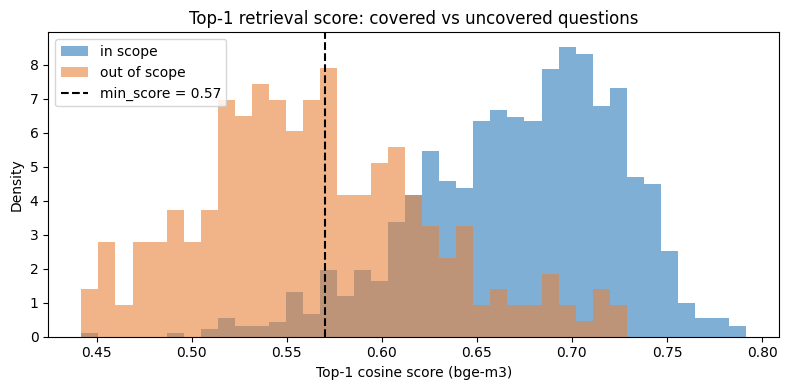

intent
availability                      0.0
availability_online               0.0
refund_policy                     0.0
order_history                     0.1
payment_methods                   0.1
return_policy                     0.1
shipping_costs                    0.2
product_information               0.5
submit_product_feedback           0.6
customer_service                  0.6
submit_feedback                   0.6
remove_product                    0.6
request_right_to_rectification    0.6
close_account                     0.7
human_agent                       0.7
pay                               0.7
add_product                       0.9
sales_period                      1.0
technical_issue                   1.0
open_account                      1.0
change_account                    1.0
submit_product_idea               1.0
recover_password                  1.0
use_app                           1.0


In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(scores.score.min(), scores.score.max(), 40)
for scope, color in [("in scope", "#2b7bba"), ("out of scope", "#e8833a")]:
    ax.hist(scores.loc[scores.scope == scope, "score"], bins=bins, alpha=0.6,
            density=True, label=scope, color=color)
ax.axvline(chosen.min_score, color="black", linestyle="--",
           label=f"min_score = {chosen.min_score:.2f}")
ax.set_xlabel("Top-1 cosine score (bge-m3)")
ax.set_ylabel("Density")
ax.set_title("Top-1 retrieval score: covered vs uncovered questions")
ax.legend()
plt.tight_layout()
EVAL_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(EVAL_DIR / "knowledge_base_score_distribution.png", dpi=150)
plt.show()

print(out_frame.assign(rejected=out_frame.top1_score < chosen.min_score)
      .groupby("intent").rejected.mean().sort_values().round(2).to_string())

## 10. Exports

In [13]:
summary.assign(test_set="bitext_in_scope").to_csv(
    EVAL_DIR / "knowledge_base_retrieval_metrics.csv", index=False)
per_intent.to_csv(EVAL_DIR / "knowledge_base_retrieval_by_intent.csv")
french_summary.to_csv(EVAL_DIR / "knowledge_base_retrieval_french.csv", index=False)
threshold_table.to_csv(EVAL_DIR / "knowledge_base_score_thresholds.csv", index=False)
print(sorted(p.name for p in EVAL_DIR.glob("knowledge_base_*")))

['knowledge_base_retrieval_by_intent.csv', 'knowledge_base_retrieval_french.csv', 'knowledge_base_retrieval_metrics.csv', 'knowledge_base_score_distribution.png', 'knowledge_base_score_thresholds.csv']


## 11. Conclusions

1. **bge-m3 finds a relevant section for 96.9% of questions** in its top 4 (hit@4, 95% CI
   [0.959, 0.978]) and ranks one first for 83.7% (hit@1). The advisor reads the top 4, so
   hit@4 is the figure that matters most.
2. **Why bge-m3 and not the small model.** In English, all-MiniLM-L6-v2 is close (hit@4
   96.3%) and 20 times faster. On French questions it collapses (hit@4 41%), while bge-m3
   keeps 100% (34 questions, illustrative). TF-IDF is far behind in both languages: Bitext
   messages are full of typos and synonyms that shared-word matching misses.
3. **Weak spots (top-1).** `delivery_issue` (18%), `track_order` (35%) and `request_refund`
   (38%). Main causes, from the error analysis:
   - "report a delivery problem" is closest to the FAQ answer about damaged or incomplete
     parcels: a neighbouring topic, arguably not wrong;
   - customers write "reimbursement", a word the documents never use; the internal
     "Compensation authority" section of the advisor playbook then comes first;
   - Bitext `track_order` includes questions about the status of a *replacement*, which pull
     the exchange section.
   Even for these intents, a relevant section is in the top 4 for 72% to 97% of questions.
4. **"No answer" threshold.** A top-1 score below **0.57** keeps 95.5% of covered questions
   and rejects every truly unrelated one (password, account, app, product ideas). General
   policy questions (`refund_policy`, `return_policy`, `shipping_costs`) are *not* rejected,
   which is correct: the documents do answer them. A score alone cannot separate "related but
   not order-linked" from "covered"; the advisor should combine it with the detected intent.
5. **Cost.** About 50 ms per question on CPU; building the index takes under a minute.

**Next steps**

- Add customer vocabulary ("reimbursement", "replacement status") to the documents, and
  evaluate on a **new** Bitext sample, since this sample was used to find the problems.
- If top-1 must improve: hybrid search (BM25 + dense) or a cross-encoder reranker
  (`bge-reranker-v2-m3`) over the top 10.
- Tag the general policy intents (`refund_policy`, `return_policy`, `shipping_costs`,
  `payment_methods`) that the documents already answer.